In [1]:
import os
from typing import Optional

from dotenv import load_dotenv
from langchain_core.utils.utils import secret_from_env
from langchain_openai import ChatOpenAI
from pydantic import Field, SecretStr

load_dotenv()

class ChatOpenRouter(ChatOpenAI):
    openai_api_key: Optional[SecretStr] = Field(
        alias="api_key", default_factory=secret_from_env("OPENROUTER_API_KEY", default=None)
    )
    @property
    def lc_secrets(self) -> dict[str, str]:
        return {"openai_api_key": "OPENROUTER_API_KEY"}

    def __init__(self,
                 openai_api_key: Optional[str] = None,
                 **kwargs):
        openai_api_key = openai_api_key or os.environ.get("OPENROUTER_API_KEY")
        super().__init__(base_url="https://openrouter.ai/api/v1", openai_api_key=openai_api_key, **kwargs)


model = ChatOpenRouter(model_name="google/gemini-2.5-flash", temperature=0.0)

/home/chen/proj/db_form_agent_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
df = pd.read_csv('/data/chen/data/hmdb/metabolites_endo_exo.csv')

In [3]:
# use model to take input compound name and return if it is endogenous metabolite from human
def is_endogenous_compound(compound_name: str) -> str:
    prompt = f"Is the compound '{compound_name}' an endogenous metabolite from human? Answer 'Endogenous', 'Exogenous', 'Unclear'."
    response = model.predict(prompt)
    return response.strip()

In [4]:
df['Endogenous_LLM'] = df['Name'].apply(is_endogenous_compound)
df[['Name', 'Origin', 'Endogenous_LLM']]

/tmp/ipykernel_2549012/3245632064.py:4: LangChainDeprecationWarning: The method `BaseChatModel.predict` was deprecated in langchain-core 0.1.7 and will be removed in 1.0. Use :meth:`~invoke` instead.
  response = model.predict(prompt)


,Name,Origin,Endogenous_LLM
0,Glucose,Endogenous,Endogenous
1,Lactate,Endogenous,Endogenous
2,Pyruvate,Endogenous,Endogenous
3,Citrate,Endogenous,Endogenous
4,Isocitrate,Endogenous,Endogenous
...,...,...,...
95,Piperine,Exogenous,Exogenous
96,Glyphosate,Exogenous,Exogenous
97,DEET,Exogenous,Exogenous
98,PFOA,Exogenous,Exogenous


In [5]:
# calculate accuracy, precision, recall and F1 score
df = df[df['Endogenous_LLM']!='Unclear']
df['Endogenous_bool'] = df['Origin'] == 'Endogenous'
df['Endogenous_LLM_bool'] = df['Endogenous_LLM'] == 'Endogenous'

accuracy = (df['Endogenous_bool'] == df['Endogenous_LLM_bool']).mean()
precision = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_LLM_bool'].sum()
recall = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

(0.9887640449438202, 0.9803921568627451, 1.0, 0.99009900990099)

<Axes: >

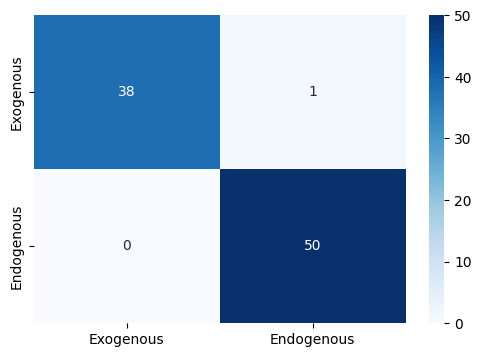

In [6]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df['Endogenous_bool'], df['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [7]:
df.to_csv('metabolites_endo_exo_llm_gemini2.5.csv', index=False)

In [17]:
import pandas as pd

df = pd.read_csv("/data/chen/data/hmdb/metabolites.csv")

In [ ]:

# get 100 rows with 80% endogenous
df_endogenous = df[df['Endogenous']=='Yes'].sample(n=45, random_state=42)
df_non_endogenous = df[df['Endogenous']=='No'].sample(n=5, random_state=42)
df_sampled = pd.concat([df_endogenous, df_non_endogenous]).reset_index(drop=True)


In [19]:
df_sampled

,Accession,Name,Description,Chemical_Formula,Average_Molecular_Weight,Monisotopic_Molecular_Weight,IUPAC_Name,Traditional_IUPAC,CAS_Registry_Number,SMILES,InChI,InChIKey,Synonyms,Ontology,Endogenous
0,HMDB0104373,TG(i-16:0/a-17:0/18:0)[rac],TG(i-16:0/a-17:0/18:0) belongs to the family o...,C54H104O6,849.4200,848.783291,(2R)-2-[(14-methylhexadecanoyl)oxy]-3-[(14-met...,(2R)-2-[(14-methylhexadecanoyl)oxy]-3-[(14-met...,NaN,[H][C@@](COC(=O)CCCCCCCCCCCCCCCCC)(COC(=O)CCCC...,InChI=1S/C54H104O6/c1-6-8-9-10-11-12-13-14-15-...,BVPZRSZXEXQZEN-HUWKAXHXSA-N,1-isohexadecanoyl-2-anteisoheptadecanoyl-3-oct...,\n,Yes
1,HMDB0068318,TG(i-22:0/i-18:0/a-25:0)[rac],TG(i-22:0/i-18:0/a-25:0) belongs to the family...,C68H132O6,1045.7980,1045.002392,(2R)-3-[(20-methylhenicosanoyl)oxy]-2-[(16-met...,(2R)-3-[(20-methylhenicosanoyl)oxy]-2-[(16-met...,NaN,[H][C@@](COC(=O)CCCCCCCCCCCCCCCCCCCCC(C)CC)(CO...,InChI=1S/C68H132O6/c1-7-64(6)56-50-44-38-32-26...,LRRRHCCXZWNSSY-VWDVLKFASA-N,1-isodocosanoyl-2-isooctadecanoyl-3-anteisopen...,\n,Yes
2,HMDB0028681,Alanylarginine,Alanylarginine is a dipeptide composed of alan...,C9H19N5O3,245.2830,245.148789,(2S)-2-[(2S)-2-aminopropanamido]-5-carbamimida...,(2S)-2-[(2S)-2-aminopropanamido]-5-carbamimida...,16709-12-9,C[C@H](N)C(=O)N[C@@H](CCCNC(N)=N)C(O)=O,InChI=1S/C9H19N5O3/c1-5(10)7(15)14-6(8(16)17)3...,SITWEMZOJNKJCH-WDSKDSINSA-N,(2S)-2-{[(2S)-2-amino-1-hydroxypropylidene]ami...,\n,Yes
3,HMDB0058341,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...","CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",C83H148O17P2,1480.0280,1479.019177,"[(2R)-3-[(4Z,7Z,10Z,13Z,16Z)-docosa-4,7,10,13,...","(2R)-3-[(4Z,7Z,10Z,13Z,16Z)-docosa-4,7,10,13,1...",NaN,[H][C@](O)(COP(O)(=O)OC[C@@]([H])(COC(=O)CCCCC...,InChI=1S/C83H148O17P2/c1-5-9-13-17-21-25-29-33...,LWOSNUHJAUNLKR-XPBBNWCYSA-N,1'-[1-Oleoyl-2-palmitoyl-sn-glycero-3-phospho]...,\n,Yes
4,HMDB0096061,TG(12:0/i-20:0/14:0),TG(12:0/i-20:0/14:0) belongs to the family of ...,C49H94O6,779.2850,778.705041,(2S)-1-(dodecanoyloxy)-3-(tetradecanoyloxy)pro...,(2S)-1-(dodecanoyloxy)-3-(tetradecanoyloxy)pro...,NaN,[H][C@](COC(=O)CCCCCCCCCCC)(COC(=O)CCCCCCCCCCC...,InChI=1S/C49H94O6/c1-5-7-9-11-13-15-20-25-29-3...,ZQCNILQMSQAMBS-DXQCBLCSSA-N,1-dodecanoyl-2-isoeicosanoyl-3-tetradecanoyl-g...,\n,Yes
5,HMDB0106341,TG(i-17:0/i-16:0/i-15:0),TG(i-17:0/i-16:0/i-15:0) belongs to the family...,C51H98O6,807.3390,806.736341,(2S)-2-[(14-methylpentadecanoyl)oxy]-3-[(13-me...,(2S)-2-[(14-methylpentadecanoyl)oxy]-3-[(13-me...,NaN,[H][C@](COC(=O)CCCCCCCCCCCCCC(C)C)(COC(=O)CCCC...,InChI=1S/C51H98O6/c1-45(2)37-31-25-19-13-8-7-9...,MMASWTMULGSPKF-DYVQZXGMSA-N,1-isoheptadecanoyl-2-isohexadecanoyl-3-isopent...,\n,Yes
6,HMDB0109242,TG(18:0/a-21:0/i-19:0)[rac],TG(18:0/a-21:0/i-19:0) belongs to the family o...,C61H118O6,947.6090,946.892842,(2S)-1-[(17-methyloctadecanoyl)oxy]-3-(octadec...,(2S)-1-[(17-methyloctadecanoyl)oxy]-3-(octadec...,NaN,[H][C@](COC(=O)CCCCCCCCCCCCCCCCC)(COC(=O)CCCCC...,InChI=1S/C61H118O6/c1-6-8-9-10-11-12-13-14-15-...,DSKIDGAMWVQQIC-ISBVVKTBSA-N,1-octadecanoyl-2-anteisoheneicosanoyl-3-isonon...,\n,Yes
7,HMDB0208762,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))","CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z)) is a...",C71H130O17P2,1317.7520,1316.878327,"[(2R)-2,3-bis[(9Z,11Z)-octadeca-9,11-dienoylox...","(2R)-2,3-bis[(9Z,11Z)-octadeca-9,11-dienoyloxy...",NaN,[H][C@](O)(COP(O)(=O)OC[C@@]([H])(COC(=O)CCCCC...,InChI=1S/C71H130O17P2/c1-6-9-12-15-18-21-24-26...,WPFJZPHIBGIBHK-ULLPMNMLSA-N,[(2S)-2-Hydroxy-3-({hydroxy[(2R)-3-[(10-methyl...,\n,Yes
8,HMDB0013881,S-4'-Hydroxywarfarin,S-4'-Hydroxywarfarin is only found in individu...,C19H16O5,324.3273,324.099774,2-hydroxy-3-[(1S)-1-(4-hydroxyphenyl)-3-oxobut...,2-hydroxy-3-[(1S)-1-(4-hydroxyphenyl)-3-oxobut...,NaN,[H][C@](CC(C)=O)(C1=CC=C(O)C=C1)C1=C(O)OC2=CC=...,InChI=1S/C19H16O5/c1-11(20)10-15(12-6-8-13(21)...,UNTPHJKCRGFOFJ-HNNXBMFYSA-N,Flora; Kidneys; Extracellular region,\n,Yes
9,HMDB0008055,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))","PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z)) is

In [20]:

df_sampled['Endogenous_LLM'] = df_sampled['Name'].apply(is_endogenous_compound)
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]

,Name,Endogenous,Endogenous_LLM
0,TG(i-16:0/a-17:0/18:0)[rac],Yes,Unclear
1,TG(i-22:0/i-18:0/a-25:0)[rac],Yes,Unclear
2,Alanylarginine,Yes,Unclear
3,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",Yes,Unclear
4,TG(12:0/i-20:0/14:0),Yes,Unclear
5,TG(i-17:0/i-16:0/i-15:0),Yes,Unclear
6,TG(18:0/a-21:0/i-19:0)[rac],Yes,Unclear
7,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))",Yes,Unclear
8,S-4'-Hydroxywarfarin,Yes,Unclear
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Yes,Endogenous


In [21]:
# unclear ratio
unclear_ratio = (df_sampled['Endogenous_LLM']=='Unclear').mean()
unclear_ratio

0.88

In [13]:
# calculate accuracy, precision, recall and F1 score
df_sampled = df_sampled[df_sampled['Endogenous_LLM']!='Unclear']
df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'

accuracy = (df_sampled['Endogenous_bool'] == df_sampled['Endogenous_LLM_bool']).mean()
precision = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_LLM_bool'].sum()
recall = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

/tmp/ipykernel_2549012/1808926640.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
/tmp/ipykernel_2549012/1808926640.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'


(0.8333333333333334, 0.5, 1.0, 0.6666666666666666)

<Axes: >

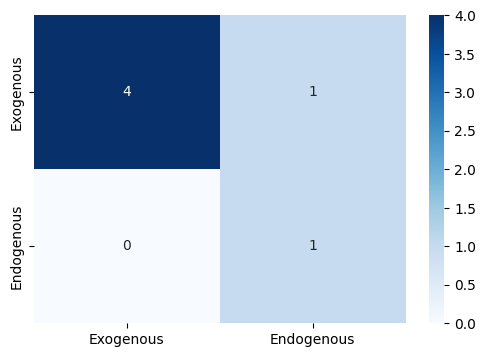

In [14]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df_sampled['Endogenous_bool'], df_sampled['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [ ]:
df_sampled.to_csv("data/metabolites_llm_labled.csv", index=False)